In [1]:
# ====================================================
# Libraries
# ====================================================

import numpy as np
import matplotlib.pyplot as plt
from getdist import MCSamples, plots

In [2]:
# ====================================================
# File paths
# ====================================================
# DMbudget robustness test: only the "with FRB" configuration is relevant here
# (the Galactic DM budget only enters through the FRB likelihood), so we
# compare the fiducial CC+SNe+BAO+FRB run against the DMbudget robustness-test
# run (DM_MW,halo and DM_MW,ISM uncertainties marginalized/propagated),
# instead of a with-FRB vs without-FRB comparison.

fname_fid   = "/home/brunowesley/projetos/MCMC-cosmo/Codes/MCMC-Models/GR-based/CPL/CC_SNe_BAO_FRB/flat_samples_CPL_cc_sne_bao_frb.npy"
fname_robust = "/home/brunowesley/projetos/MCMC-cosmo/Codes/Robustness-test/CPL/CC_SNe_BAO_FRB/flat_samples_CPL_cc_sne_bao_frb_DMbudget.npy"

# ====================================================
# Load samples
# ====================================================

samples_fid_full   = np.load(fname_fid)
samples_robust_full = np.load(fname_robust)

print("Fiducial (CC+SNe+BAO+FRB):           ", samples_fid_full.shape)
print("DMbudget robustness test (CC+SNe+BAO+FRB):", samples_robust_full.shape)

Fiducial (CC+SNe+BAO+FRB):            (3179072, 8)
DMbudget robustness test (CC+SNe+BAO+FRB): (427520, 8)


In [3]:
# ====================================================
# Function: marginalized statistics (PRINT + SAVE)
# ====================================================

def print_stats(flat_samples, param_names_indices, fmt_map, title, file=None):

    lines = []
    lines.append("\n" + "="*60)
    lines.append(f"{title:^60}")
    lines.append("="*60)

    for name, idx in param_names_indices:
        samples = flat_samples[:, idx]

        median  = np.percentile(samples, 50)
        lower68 = np.percentile(samples, 16)
        upper68 = np.percentile(samples, 84)
        lower95 = np.percentile(samples, 2.5)
        upper95 = np.percentile(samples, 97.5)

        ep68 = upper68 - median
        em68 = median  - lower68
        ep95 = upper95 - median
        em95 = median  - lower95

        fmt = fmt_map.get(name, ".3f")

        lines.append(f"\n  {name}:")
        lines.append(f"    {median:{fmt}} +{ep68:{fmt}} -{em68:{fmt}}  (68% CL)")
        lines.append(f"    {median:{fmt}} +{ep95:{fmt}} -{em95:{fmt}}  (95% CL)")

    lines.append("\n" + "="*60)

    for line in lines:
        print(line)

    if file is not None:
        for line in lines:
            file.write(line + "\n")


# ====================================================
# Save ALL output
# ====================================================
# DMbudget robustness test: both chains use the same 8-parameter FRB model
# (H0, Om0, Ob, MB, w0, wa, sigma_host, exp_mu), so a single param/format
# map covers both -- no separate "no FRB" branch needed here.

output_file = "stats_CPL_DMbudget.txt"

param_FRB = [
    ("H0", 0),
    ("Om0", 1),
    ("Ob", 2),
    ("MB", 3),
    ("w0", 4),
    ("wa", 5),
    ("sigma_host", 6),
    ("exp_mu", 7)
]

fmt_FRB = {
    "H0": ".2f",
    "Om0": ".3f",
    "Ob": ".4f",
    "MB": ".3f",
    "w0": ".3f",
    "wa": ".3f",
    "sigma_host": ".3f",
    "exp_mu": ".1f"
}

with open(output_file, "w", encoding="utf-8") as f:

    # ====================================================
    # Statistics: Fiducial (DM_MW,halo = 50 pc/cm^3 fixed,
    # DM_MW,ISM point estimate, no propagated systematic uncertainty)
    # ====================================================

    print_stats(
        samples_fid_full,
        param_FRB,
        fmt_FRB,
        "CPL | CC + SNe + BAO + FRB (Fiducial)",
        file=f
    )

    # ====================================================
    # Statistics: DMbudget robustness test (DM_MW,halo marginalized via
    # P_halo, DM_MW,ISM uncertainty sigma_MW added in quadrature)
    # ====================================================

    print_stats(
        samples_robust_full,
        param_FRB,
        fmt_FRB,
        "CPL | CC + SNe + BAO + FRB (DMbudget robustness test)",
        file=f
    )

print(f"\n✅ Full output saved to: {output_file}")


           CPL | CC + SNe + BAO + FRB (Fiducial)            

  H0:
    68.20 +1.36 -1.40  (68% CL)
    68.20 +2.66 -2.80  (95% CL)

  Om0:
    0.306 +0.013 -0.014  (68% CL)
    0.306 +0.024 -0.028  (95% CL)

  Ob:
    0.0543 +0.0030 -0.0028  (68% CL)
    0.0543 +0.0061 -0.0053  (95% CL)

  MB:
    -19.386 +0.043 -0.045  (68% CL)
    -19.386 +0.082 -0.091  (95% CL)

  w0:
    -0.842 +0.060 -0.057  (68% CL)
    -0.842 +0.123 -0.109  (95% CL)

  wa:
    -0.261 +0.327 -0.371  (68% CL)
    -0.261 +0.597 -0.761  (95% CL)

  sigma_host:
    0.851 +0.132 -0.108  (68% CL)
    0.851 +0.283 -0.195  (95% CL)

  exp_mu:
    98.6 +17.0 -16.7  (68% CL)
    98.6 +33.9 -32.2  (95% CL)


   CPL | CC + SNe + BAO + FRB (DMbudget robustness test)    

  H0:
    68.19 +1.38 -1.39  (68% CL)
    68.19 +2.69 -2.77  (95% CL)

  Om0:
    0.305 +0.013 -0.014  (68% CL)
    0.305 +0.024 -0.028  (95% CL)

  Ob:
    0.0543 +0.0030 -0.0028  (68% CL)
    0.0543 +0.0062 -0.0054  (95% CL)

  MB:
    -19.387 +0.043 -0.0

Removed no burn in


Removed no burn in


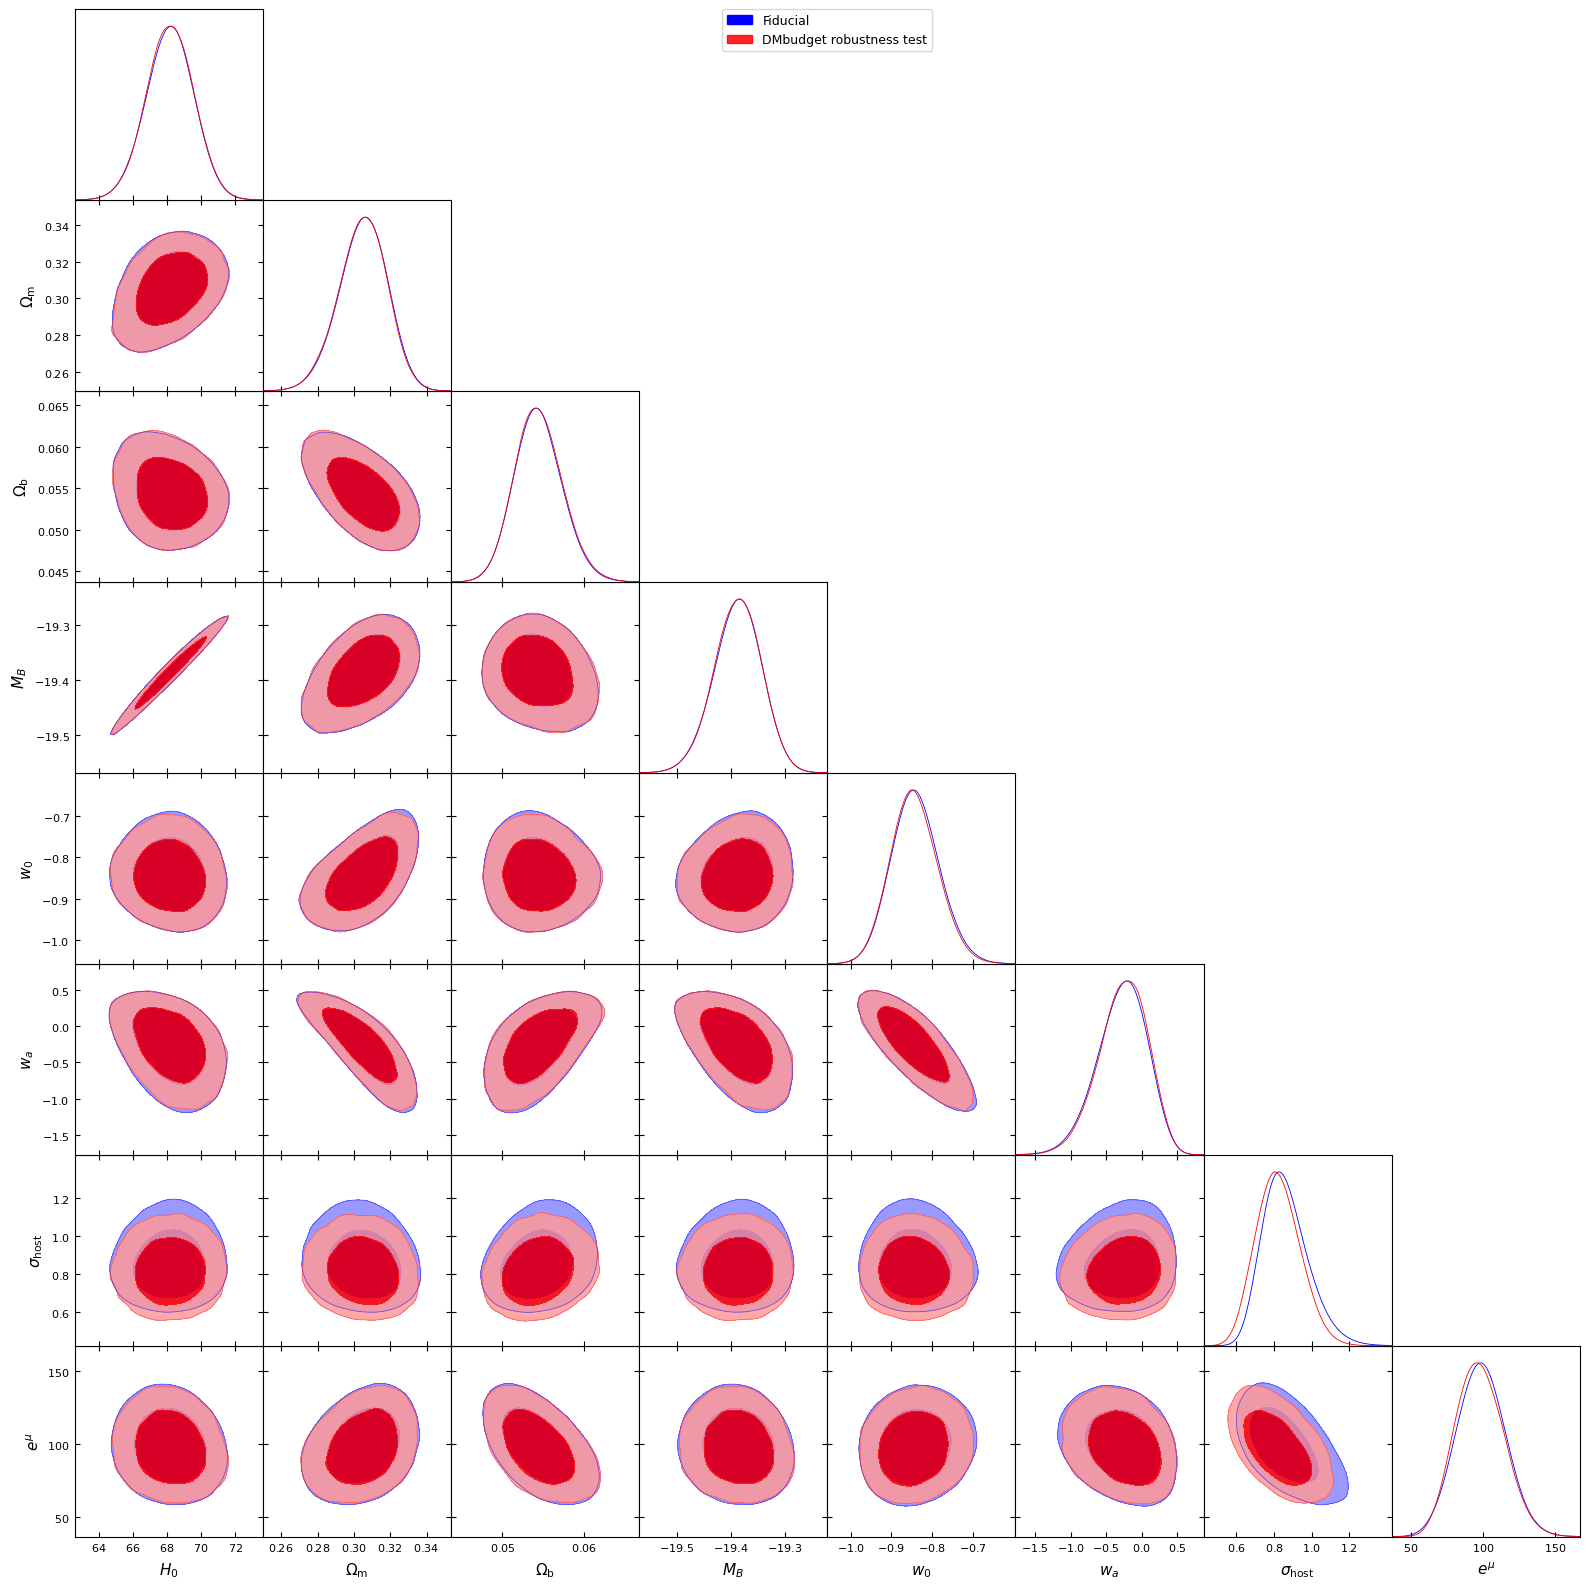

In [4]:
# ====================================================
# Parameters for corner plot
# ====================================================
# Both chains share the same 8-parameter FRB model, so no column
# subsetting is needed here (unlike the fiducial no-FRB vs FRB
# comparison, which had to restrict to the 6 shared parameters).

param_names  = ["H0", "Om0", "Ob", "MB", "w0", "wa", "sigma_host", "exp_mu"]
param_labels = [r"H_0", r"\Omega_{\rm m}", r"\Omega_{\rm b}",
                r"M_B", r"w_0", r"w_a", r"\sigma_{\rm host}", r"e^\mu"]

# ====================================================
# GetDist
# ====================================================

gd_fid   = MCSamples(samples=samples_fid_full,
                     names=param_names,
                     labels=param_labels)

gd_robust = MCSamples(samples=samples_robust_full,
                     names=param_names,
                     labels=param_labels)

for gd in [gd_fid, gd_robust]:
    gd.updateSettings({
        "smooth_scale_1D": 0.25,
        "smooth_scale_2D": 0.25,
        "fine_bins": 1024,
        "fine_bins_2D": 1024,
    })

# ====================================================
# Corner plot
# ====================================================

g = plots.get_subplot_plotter()

g.triangle_plot(
    [gd_fid, gd_robust],
    filled=True,
    legend_labels=[r"Fiducial", r"DMbudget robustness test"],
    contour_colors=["blue", "red"],
    title_limit=0
)

plt.savefig("Corner_CPL_DMbudget.png", dpi=300, bbox_inches="tight")
plt.savefig("Corner_CPL_DMbudget.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
# ========================================================
# Derived Parameter: Sound Horizon rd
# ========================================================

Neff = 3.046 

def compute_rd_chain(flat_samples):
    H0  = flat_samples[:, 0]
    Om0 = flat_samples[:, 1]
    Ob  = flat_samples[:, 2]

    h2   = (H0 / 100.0)**2
    Obh2 = Ob * h2
    Omh2 = Om0 * h2

    rd = 147.05 * ((Obh2 / 0.02236)**-0.13) \
                 * ((Omh2 / 0.1432)**-0.23) \
                 * ((Neff  / 3.04)**-0.1)

    return rd


def print_rd_stats(rd_chain, title):

    median  = np.percentile(rd_chain, 50)
    lower68 = np.percentile(rd_chain, 16)
    upper68 = np.percentile(rd_chain, 84)
    lower95 = np.percentile(rd_chain, 2.5)
    upper95 = np.percentile(rd_chain, 97.5)

    ep68 = upper68 - median
    em68 = median  - lower68
    ep95 = upper95 - median
    em95 = median  - lower95

    print("\n" + "="*60)
    print(f"{title:^60}")
    print("="*60)

    print(f"\n  r_d:")
    print(f"    {median:.3f} +{ep68:.3f} -{em68:.3f}  (68% CL)")
    print(f"    {median:.3f} +{ep95:.3f} -{em95:.3f}  (95% CL)")

    print("\n" + "="*60)


# ========================================================
# Compute rd for both chains
# ========================================================

rd_fid   = compute_rd_chain(samples_fid_full)
rd_robust = compute_rd_chain(samples_robust_full)


# ========================================================
# Print results
# ========================================================

print_rd_stats(rd_fid,   "Sound Horizon r_d | Fiducial (CC + SNe + BAO + FRB)")
print_rd_stats(rd_robust, "Sound Horizon r_d | DMbudget robustness test (CC + SNe + BAO + FRB)")


    Sound Horizon r_d | Fiducial (CC + SNe + BAO + FRB)     

  r_d:
    145.010 +2.829 -2.608  (68% CL)
    145.010 +5.834 -4.966  (95% CL)


Sound Horizon r_d | DMbudget robustness test (CC + SNe + BAO + FRB)

  r_d:
    145.027 +2.812 -2.593  (68% CL)
    145.027 +5.770 -4.958  (95% CL)

